## 대여소 한 곳의 한 블록을 한 행으로 읽기

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
figures = root / "results/figures"
tables = root / "results/eda"
for folder in (figures, tables):
    folder.mkdir(parents=True, exist_ok=True)
for family in ("AppleGothic", "Malgun Gothic", "Noto Sans CJK KR", "Noto Sans CJK JP"):
    if family in font_manager.get_font_names():
        plt.rcParams["font.family"] = family
        break
plt.rcParams.update({"axes.unicode_minus": False, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.figsize": (8, 4.6)})
teal, coral = "#087e83", "#c25b38"
blocks = ["00–06", "06–10", "10–16", "16–20", "20–24"]

def finish(ax, name, title, xlabel, ylabel):
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.figure.tight_layout()
    ax.figure.savefig(figures / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(ax.figure)

d = pd.read_csv(root / "data/processed/train.csv", parse_dates=["date"])
print(len(d), d.station_id.nunique(), d.date.min(), d.date.max())
assert not d.duplicated(["station_id", "date", "block"]).any()
assert d.notna().all().all()
assert (d.net_out == d.rentals - d.returns).all()
d["magnitude"] = d.net_out.abs()


3428940 2716 2025-07-03 00:00:00 2026-03-13 00:00:00


## 01 · 순유출의 중심과 꼬리

count    3.428940e+06
mean     3.948130e-02
std      6.854600e+00
min     -2.260000e+02
25%     -2.000000e+00
50%      0.000000e+00
75%      2.000000e+00
max      1.730000e+02
Name: net_out, dtype: float64 0 비율 0.22048767257519816


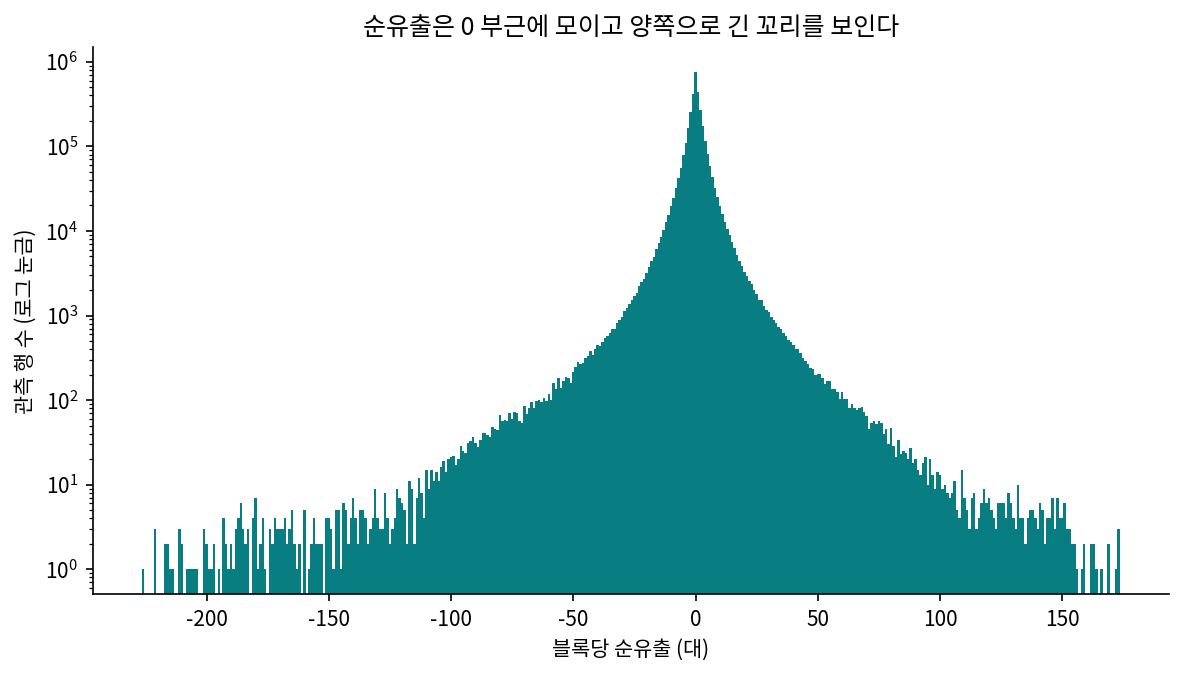

In [2]:
freq = d.net_out.value_counts().sort_index()
freq.to_csv(tables / "net_distribution.csv")
ax = plt.subplots()[1]
ax.bar(freq.index, freq, color=teal, width=1)
ax.set_yscale("log")
finish(ax, "01_distribution", "순유출은 0 부근에 모이고 양쪽으로 긴 꼬리를 보인다", "블록당 순유출 (대)", "관측 행 수 (로그 눈금)")
print(d.net_out.describe(), "0 비율", (d.net_out == 0).mean())


## 02 · 시간 블록별 대여와 반납 강도

         대여    반납
00–06  0.38  0.40
06–10  1.74  1.66
10–16  1.43  1.38
16–20  2.54  2.50
20–24  1.44  1.57


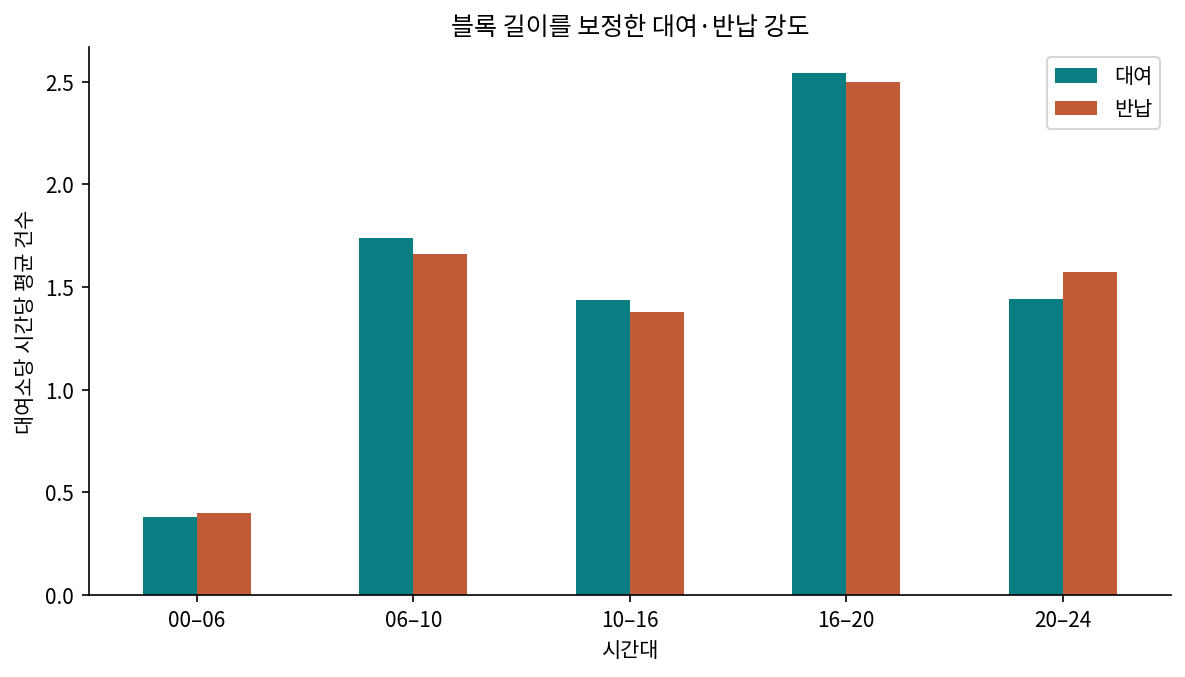

In [3]:
traffic = d.groupby("block")[["rentals", "returns"]].mean()
hours = pd.Series([6, 4, 6, 4, 4], index=traffic.index)
traffic = traffic.div(hours, axis=0)
traffic.index = blocks
traffic.columns = ["대여", "반납"]
ax = traffic.plot.bar(color=[teal, coral], rot=0)
finish(ax, "02_traffic", "블록 길이를 보정한 대여·반납 강도", "시간대", "대여소당 시간당 평균 건수")
print(traffic.round(2))


## 03 · 요일과 시간대가 만나는 지점

block       0     1     2     3     4
weekday                              
0        1.41  6.07  2.50  4.98  3.01
1        1.43  6.76  2.52  5.17  3.34
2        1.56  6.71  2.64  4.99  3.22
3        1.54  6.29  2.68  5.15  3.32
4        1.60  6.28  2.75  4.51  2.88
5        1.62  2.21  3.28  2.68  2.77
6        1.75  1.89  3.26  2.72  2.69


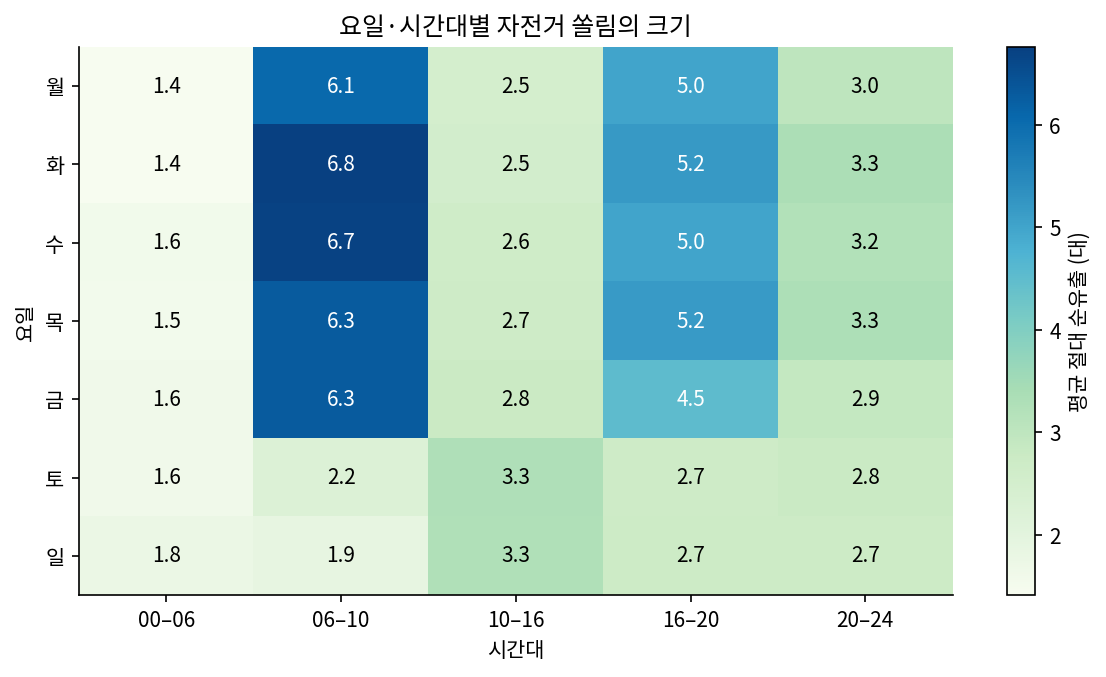

In [4]:
heat = d.pivot_table(index="weekday", columns="block", values="magnitude", aggfunc="mean")
ax = plt.subplots()[1]
im = ax.imshow(heat, aspect="auto", cmap="GnBu")
ax.set_xticks(range(5), blocks)
ax.set_yticks(range(7), list("월화수목금토일"))
for day in range(7):
    for b in range(5):
        ax.text(b, day, f"{heat.iloc[day,b]:.1f}", ha="center", va="center",
                color="white" if heat.iloc[day,b] > (heat.min().min()+heat.max().max())/2 else "black")
ax.figure.colorbar(im, ax=ax, label="평균 절대 순유출 (대)")
finish(ax, "03_weekday_block", "요일·시간대별 자전거 쏠림의 크기", "시간대", "요일")
print(heat.round(2))


## 04 · 날짜별 변화

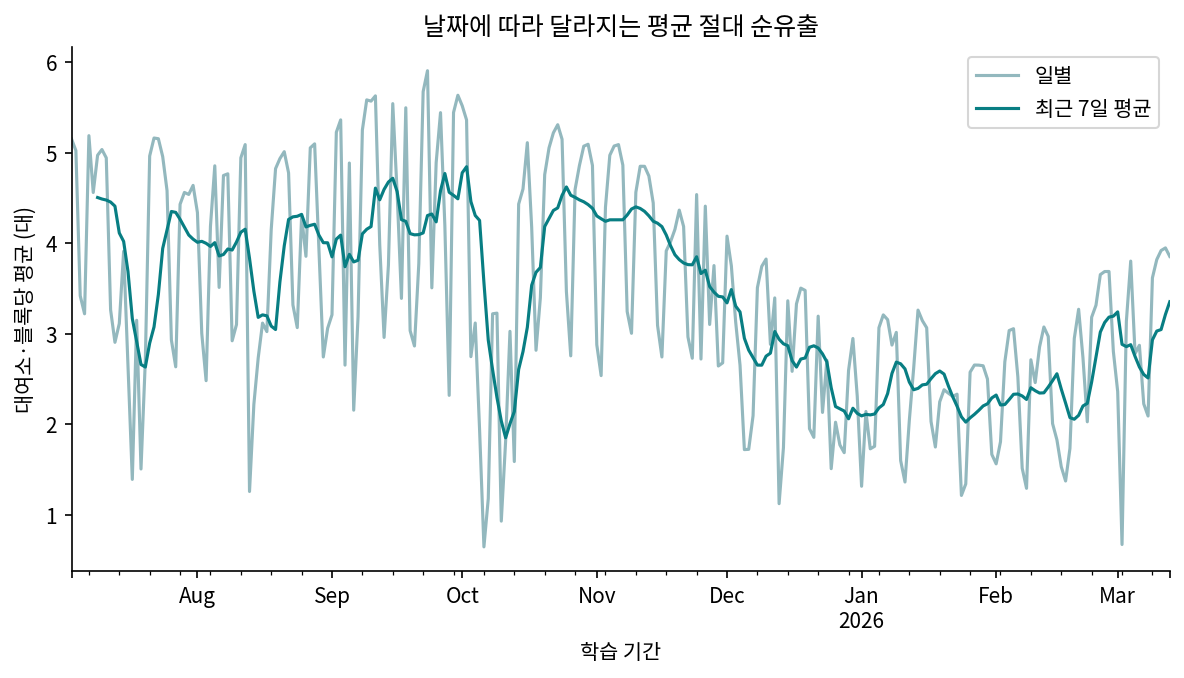

In [5]:
daily = d.groupby("date").magnitude.mean()
ax = daily.plot(color="#93b8be", label="일별")
daily.rolling(7, min_periods=7).mean().plot(ax=ax, color=teal, label="최근 7일 평균")
ax.legend()
finish(ax, "04_daily", "날짜에 따라 달라지는 평균 절대 순유출", "학습 기간", "대여소·블록당 평균 (대)")


## 05 · 강수와 이용량

        무강수    강수
00–06  0.83  0.52
06–10  3.70  1.75
10–16  3.00  1.51
16–20  5.40  2.90
20–24  3.29  1.12


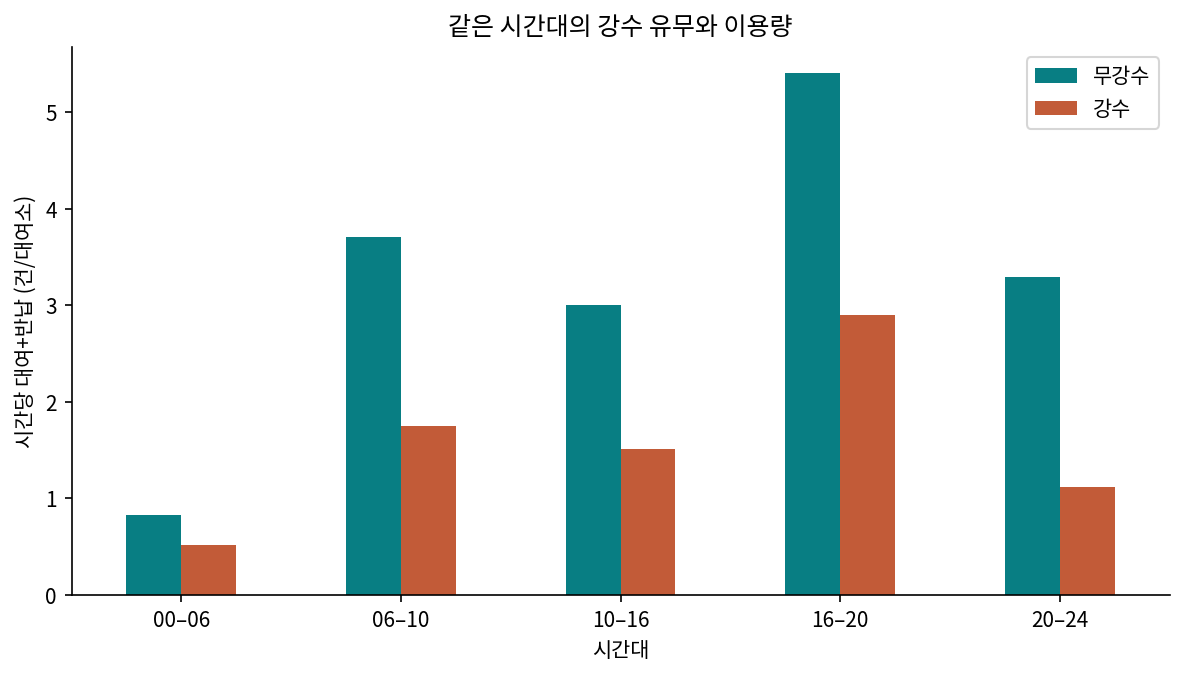

In [6]:
hourly = (d.rentals + d.returns) / d.block.map(hours)
rain = pd.DataFrame({"block": d.block, "rain": d.rain_mm.gt(0), "traffic": hourly})
wet = rain.pivot_table(index="block", columns="rain", values="traffic")
wet.columns = ["무강수", "강수"]
wet.index = blocks
ax = wet.plot.bar(rot=0, color=[teal, coral])
finish(ax, "05_rain", "같은 시간대의 강수 유무와 이용량", "시간대", "시간당 대여+반납 (건/대여소)")
print(wet.round(2))


## 06 · 대여소별 공간 분포

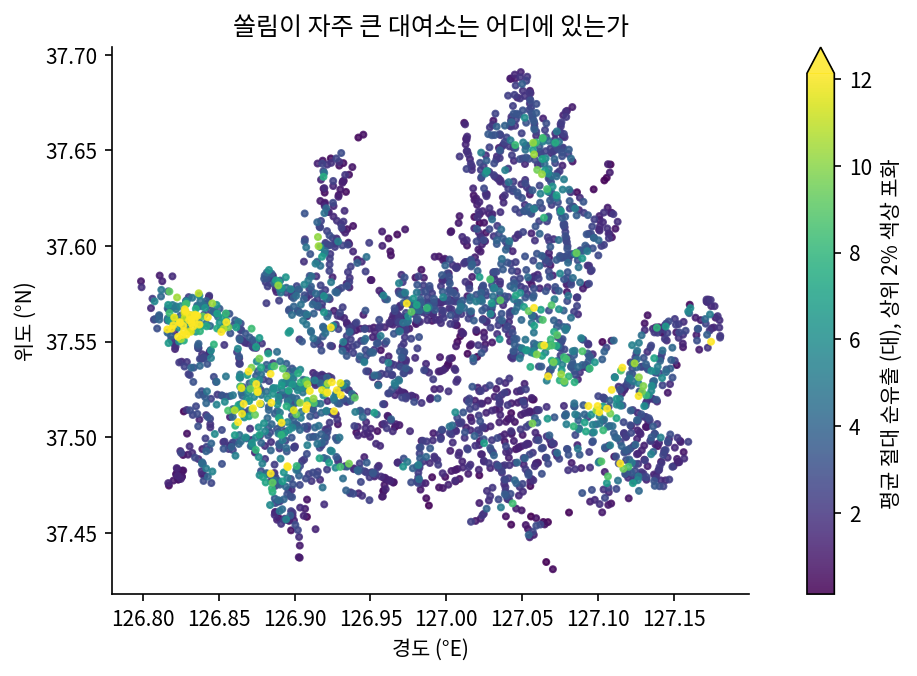

In [7]:
stations = d.groupby("station_id").agg(lat=("lat","first"), lon=("lon","first"),
                                        magnitude=("magnitude","mean"), rows=("net_out","size"))
ax = plt.subplots()[1]
ordered = stations.sort_values("magnitude")
dots = ax.scatter(ordered.lon, ordered.lat, c=ordered.magnitude, cmap="viridis",
                  s=8, alpha=.85, vmax=stations.magnitude.quantile(.98))
ax.set_aspect(1 / np.cos(np.deg2rad(37.55)))
ax.figure.colorbar(dots, ax=ax, extend="max", label="평균 절대 순유출 (대), 상위 2% 색상 포화")
finish(ax, "06_stations", "쏠림이 자주 큰 대여소는 어디에 있는가", "경도 (°E)", "위도 (°N)")


## 07 · 지난 블록과 전날의 예측 단서

       직전 블록  전일 같은 블록
00–06   0.13      0.34
06–10  -0.01      0.75
10–16   0.07      0.32
16–20  -0.04      0.59
20–24   0.19      0.58


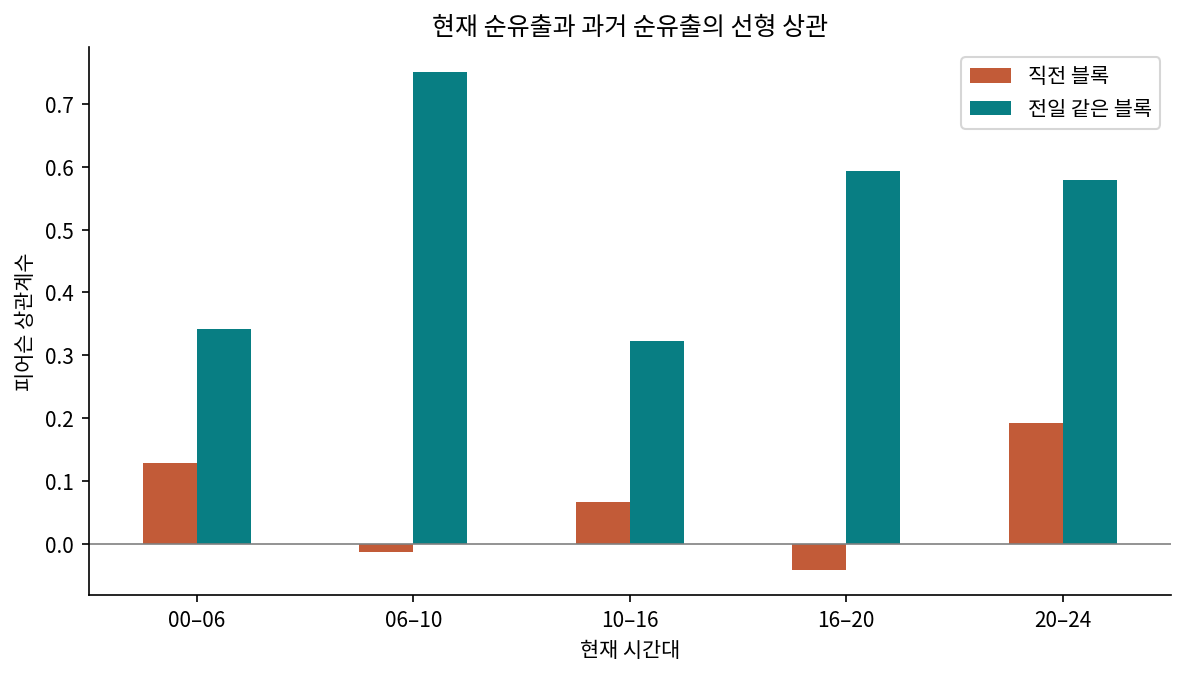

In [8]:
corr = d.groupby("block").apply(lambda part: part[["net_out","net_prev_block","net_prev_day"]]
                                .corr()["net_out"].drop("net_out"), include_groups=False)
corr.index = blocks
corr.columns = ["직전 블록", "전일 같은 블록"]
ax = corr.plot.bar(rot=0, color=[coral, teal])
ax.axhline(0, color="gray", lw=.8)
finish(ax, "07_lags", "현재 순유출과 과거 순유출의 선형 상관", "현재 시간대", "피어슨 상관계수")
print(corr.round(2))


## 08 · 극단값의 대여·반납 내역

station_id       date  block  rentals  returns  net_out  docks
   ST-2031 2025-10-19      2      162      388     -226   25.0
   ST-2033 2025-09-09      1       17      238     -221   62.0
   ST-2033 2025-09-23      1       31      252     -221   62.0
   ST-2033 2025-09-15      3      208       35      173   62.0
   ST-3251 2025-07-24      3      182        9      173   57.0
   ST-3251 2025-09-11      3      187       14      173   57.0


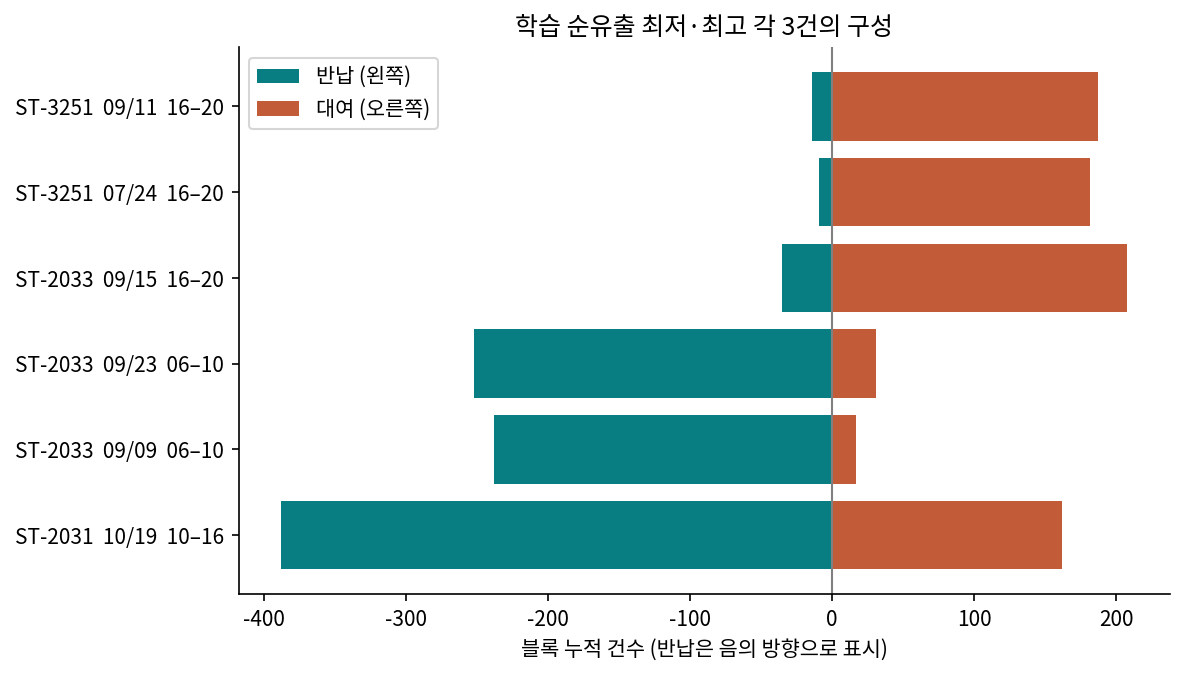

In [9]:
extreme = pd.concat([d.nsmallest(3, "net_out"), d.nlargest(3, "net_out")])
cols = ["station_id","date","block","rentals","returns","net_out","docks"]
extreme[cols].to_csv(tables / "train_extremes.csv", index=False)
labels = [f"{r.station_id}  {r.date:%m/%d}  {blocks[r.block]}" for r in extreme.itertuples()]
ax = plt.subplots()[1]
ax.barh(labels, -extreme.returns, color=teal, label="반납 (왼쪽)")
ax.barh(labels, extreme.rentals, color=coral, label="대여 (오른쪽)")
ax.axvline(0, color="gray", lw=1)
ax.legend()
finish(ax, "08_extremes", "학습 순유출 최저·최고 각 3건의 구성", "블록 누적 건수 (반납은 음의 방향으로 표시)", "")
print(extreme[cols].to_string(index=False))


## 09 · Random Forest가 분할에 사용한 변수

feature
net_prev_block    0.042534
lon               0.048304
weekday           0.080168
net_prev_day      0.615092
Name: importance, dtype: float64


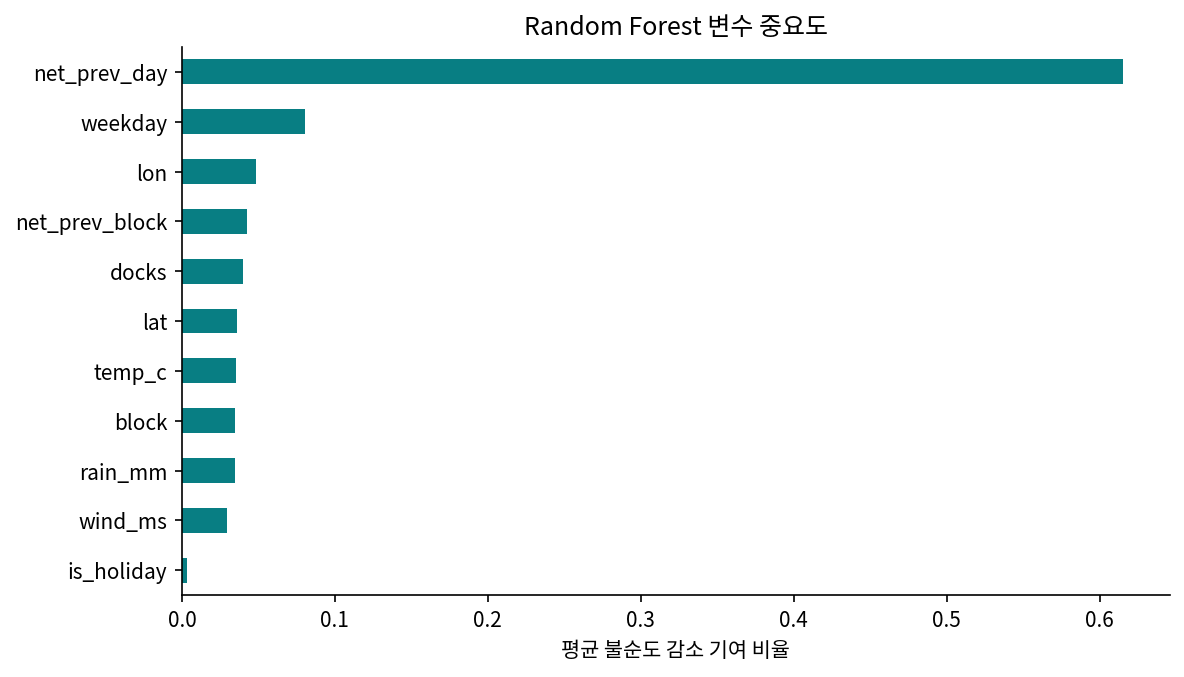

In [10]:
importance = pd.read_csv(tables / "rf_importance.csv", index_col=0).importance.sort_values()
ax = importance.plot.barh(color=teal)
finish(ax, "09_rf_importance", "Random Forest 변수 중요도", "평균 불순도 감소 기여 비율", "")
print(importance.tail(4))


## 10 · 어떤 시간대의 예측이 어려운가

00–06    1.60
06–10    3.67
10–16    3.35
16–20    4.38
20–24    2.88
Name: MAE, dtype: float64


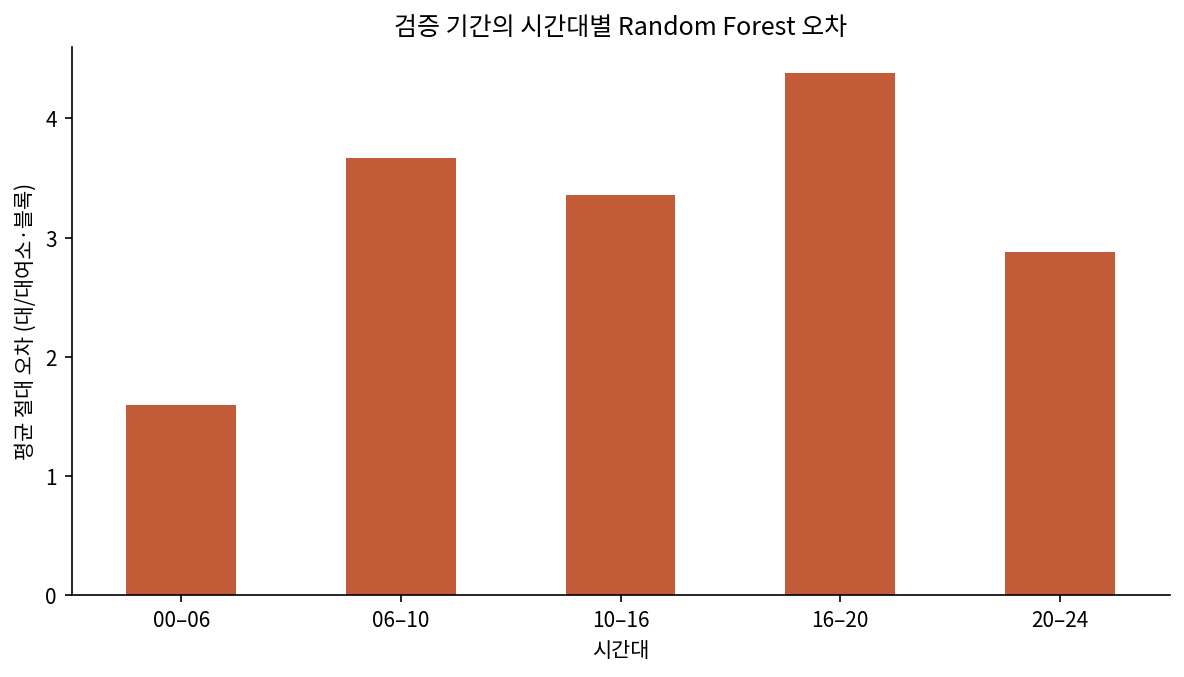

In [11]:
errors = pd.read_csv(tables / "rf_val_block_mae.csv").set_index("block").MAE
errors.index = blocks
ax = errors.plot.bar(color=coral, rot=0)
finish(ax, "10_rf_block_error", "검증 기간의 시간대별 Random Forest 오차", "시간대", "평균 절대 오차 (대/대여소·블록)")
print(errors.round(2))
